In [1]:
!pip install tensorflow scikit-learn xgboost pandas numpy matplotlib seaborn

In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    average_precision_score,
    precision_recall_curve
)

from xgboost import XGBClassifier

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [3]:
#  Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True)
#  This class imbalance is why accuracy alone is not enough: 
# a model that predicts “No” for every customer can have high accuracy 
# while finding very few churners.

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [10]:
# Clean the data
# Remove the customer ID; it is an identifier, not a useful feature
df = df.drop(columns=["customerID"])

# Convert TotalCharges to numeric
# Some values may be blank strings
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
missing_total_charges = df[df["TotalCharges"].isnull()]
missing_total_charges[["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [12]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [13]:
df.isnull().sum().sum()

np.int64(0)

In [14]:
# Encode the target
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [15]:
# Separate features and target

X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [16]:
# Create train, validation, and test sets
# First split: separate 20% as the final test set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: take 25% of the remaining data as validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (4225, 19)
Validation set: (1409, 19)
Test set: (1409, 19)


In [21]:
# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object","str"]).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [22]:
# Build a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ]
)

In [23]:
# Transform the data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (4225, 45)
Processed validation shape: (1409, 45)
Processed test shape: (1409, 45)


In [24]:
#  Build the ANN
ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    
    Dense(64, activation='relu'),
    Dropout(0.3),
    
    Dense(32, activation='relu'),
    Dropout(0.2),
    
    Dense(1, activation='sigmoid')
    
])


ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           2,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Architecture

# Processed features
#         ↓
# Dense: 64 neurons + ReLU
#         ↓
# Dropout: 30%
#         ↓
# Dense: 32 neurons + ReLU
#         ↓
# Dropout: 20%
#         ↓
# Dense: 1 neuron + sigmoid

In [27]:
# Compile the ANN
ann_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

In [28]:
# Train the ANN
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history_ann = ann_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7531 - loss: 0.4974 - pr_auc: 0.4977 - precision: 0.5490 - recall: 0.3898 - val_accuracy: 0.8041 - val_loss: 0.4358 - val_pr_auc: 0.6263 - val_precision: 0.6623 - val_recall: 0.5348
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7946 - loss: 0.4390 - pr_auc: 0.6151 - precision: 0.6339 - recall: 0.5343 - val_accuracy: 0.7991 - val_loss: 0.4318 - val_pr_auc: 0.6279 - val_precision: 0.6327 - val_recall: 0.5802
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7948 - loss: 0.4293 - pr_auc: 0.6282 - precision: 0.6377 - recall: 0.5245 - val_accuracy: 0.8020 - val_loss: 0.4325 - val_pr_auc: 0.6280 - val_precision: 0.6599 - val_recall: 0.5241
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7986 - loss: 0.4214 - pr_auc: 0.6338 - precision: 0.6436 - recall: 0.5397 - val_accuracy: 0.8055 - val_loss: 0.4315 - val_pr_auc: 0.6301 - val_precision: 0.6689 - val_recall: 0.5294
Epoc

Epoch 29: early stopping
Restoring model weights from the end of the best epoch: 19.


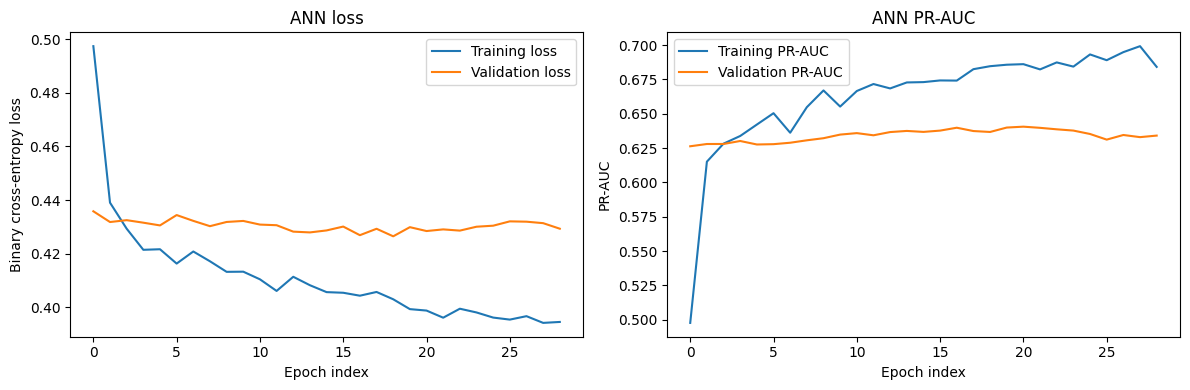

In [29]:
# Plot ANN learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history["loss"], label="Training loss")
plt.plot(history_ann.history["val_loss"], label="Validation loss")
plt.title("ANN loss")
plt.xlabel("Epoch index")
plt.ylabel("Binary cross-entropy loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ann.history["pr_auc"], label="Training PR-AUC")
plt.plot(history_ann.history["val_pr_auc"], label="Validation PR-AUC")
plt.title("ANN PR-AUC")
plt.xlabel("Epoch index")
plt.ylabel("PR-AUC")
plt.legend()

plt.tight_layout()
plt.show()

In [30]:
# Get validation probabilities
y_val_prob_ann = ann_model.predict(X_val_processed, verbose=0).ravel()

print("Validation probability examples:")
print(y_val_prob_ann[:10])

Validation probability examples:
[0.53999555 0.77342653 0.6055733  0.5960724  0.01610975 0.22897385
 0.01367751 0.01268001 0.81447494 0.00160149]


In [48]:
#  Choose the best threshold
thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob_ann >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, y_val_pred, zero_division=0),
        "recall": recall_score(y_val, y_val_pred, zero_division=0),
        "f1": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,threshold,precision,recall,f1
0,0.10,0.387528,0.930481,0.547170
1,0.11,0.397701,0.925134,0.556270
2,0.12,0.407320,0.922460,0.565111
3,0.13,0.412545,0.914439,0.568579
4,0.14,0.417284,0.903743,0.570946
...,...,...,...,...
76,0.86,0.846154,0.029412,0.056848
77,0.87,0.800000,0.021390,0.041667
78,0.88,0.600000,0.008021,0.015831
79,0.89,0.666667,0.005348,0.010610


In [49]:
# Find the threshold with the highest F1:best_row = threshold_results.loc[threshold_results["f1"].idxmax()]

best_threshold = best_row["threshold"]

print(f"Best threshold by F1: {best_threshold:.2f}")
print(best_row)

Best threshold by F1: 0.33
threshold    0.330000
precision    0.584071
recall       0.705882
f1           0.639225
Name: 23, dtype: float64


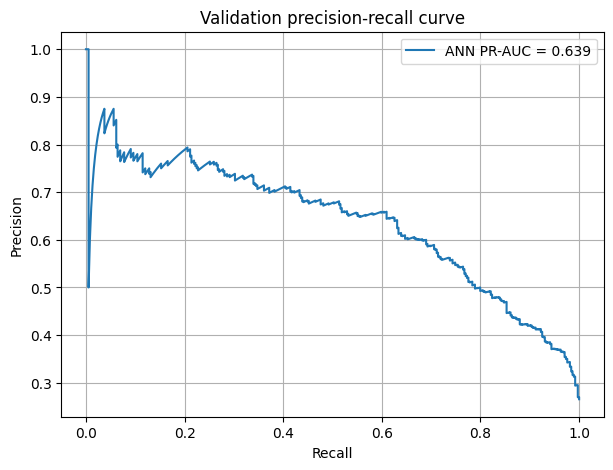

In [51]:
# plot the precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob_ann
)

pr_auc = average_precision_score(y_val, y_val_prob_ann)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"ANN PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curve")
plt.legend()
plt.grid(True)
plt.show()

In [52]:
# Create an evaluation function

def evaluate_model(y_true, y_prob, threshold=0.5, model_name="Model"):
    y_pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    pr_auc = average_precision_score(y_true, y_prob)

    print(f"\n{model_name}")
    print(f"Threshold: {threshold:.2f}")
    print(f"Accuracy:  {accuracy:.2%}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"PR-AUC:    {pr_auc:.4f}")

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No churn", "Churn"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"{model_name} confusion matrix")
    plt.show()

    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "PR-AUC": pr_auc
    }


ANN (validation)
Threshold: 0.33
Accuracy:  78.85%
Precision: 0.5841
Recall:    0.7059
F1-score:  0.6392
PR-AUC:    0.6385


<Figure size 500x400 with 0 Axes>

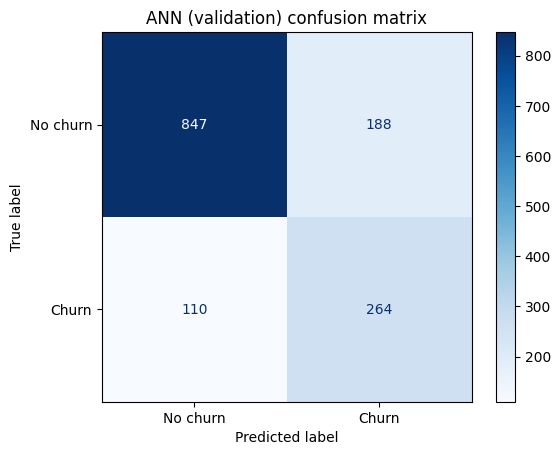

In [54]:
#  Evaluate the ANN on validation data
ann_validation_result = evaluate_model(
    y_val,
    y_val_prob_ann,
    threshold=best_threshold,
    model_name="ANN (validation)"
)

In [55]:
# Build logistic regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde


Logistic regression (validation)
Threshold: 0.33
Accuracy:  65.44%
Precision: 0.4275
Recall:    0.8904
F1-score:  0.5776
PR-AUC:    0.6426


<Figure size 500x400 with 0 Axes>

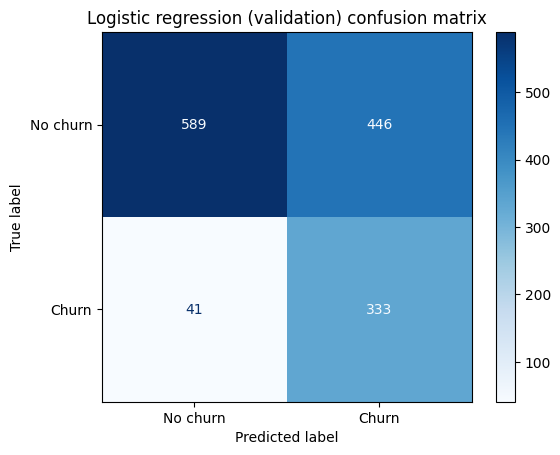

In [56]:
# Evaluate logistic regression
y_val_prob_logistic = logistic_model.predict_proba(X_val)[:, 1]

logistic_validation_result = evaluate_model(
    y_val,
    y_val_prob_logistic,
    threshold=best_threshold,
    model_name="Logistic regression (validation)"
)

In [57]:
# Build XGBoost
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde


XGBoost (validation)
Threshold: 0.33
Accuracy:  77.79%
Precision: 0.5626
Recall:    0.7326
F1-score:  0.6365
PR-AUC:    0.6427


<Figure size 500x400 with 0 Axes>

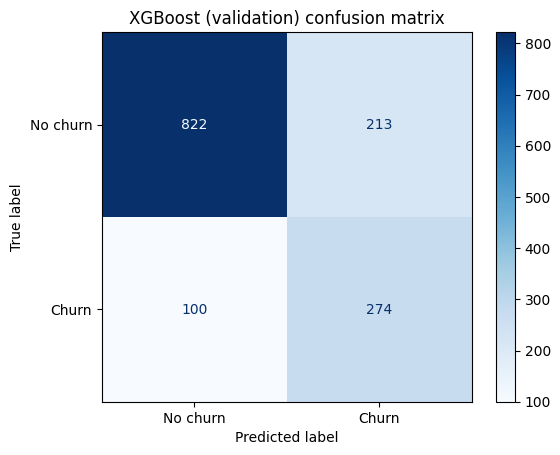

In [58]:
#  Evaluate XGBoost
y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

xgb_validation_result = evaluate_model(
    y_val,
    y_val_prob_xgb,
    threshold=best_threshold,
    model_name="XGBoost (validation)"
)

In [59]:
# compare validation results
validation_results = pd.DataFrame([
    ann_validation_result,
    logistic_validation_result,
    xgb_validation_result
])

validation_results

,Model,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
0,ANN (validation),0.33,0.788502,0.584071,0.705882,0.639225,0.638501
1,Logistic regression (validation),0.33,0.654365,0.427471,0.890374,0.577624,0.642583
2,XGBoost (validation),0.33,0.777857,0.562628,0.732620,0.636469,0.642656


In [60]:
validation_results.sort_values("F1", ascending=False)

,Model,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
0,ANN (validation),0.33,0.788502,0.584071,0.705882,0.639225,0.638501
2,XGBoost (validation),0.33,0.777857,0.562628,0.732620,0.636469,0.642656
1,Logistic regression (validation),0.33,0.654365,0.427471,0.890374,0.577624,0.642583



ANN (test)
Threshold: 0.33
Accuracy:  77.00%
Precision: 0.5530
Recall:    0.6979
F1-score:  0.6170
PR-AUC:    0.6411


<Figure size 500x400 with 0 Axes>

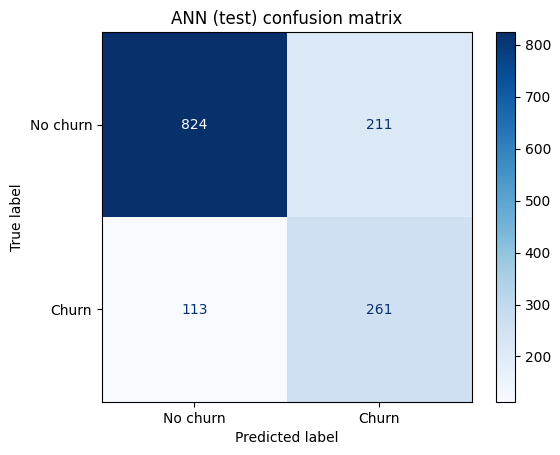


Logistic regression (test)
Threshold: 0.33
Accuracy:  66.93%
Precision: 0.4406
Recall:    0.9118
F1-score:  0.5941
PR-AUC:    0.6331


<Figure size 500x400 with 0 Axes>

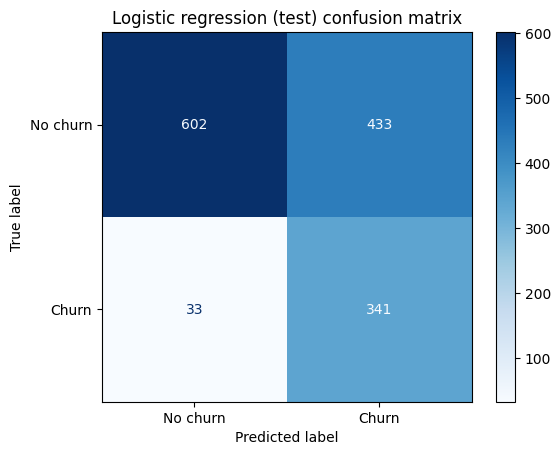


XGBoost (test)
Threshold: 0.33
Accuracy:  77.71%
Precision: 0.5625
Recall:    0.7219
F1-score:  0.6323
PR-AUC:    0.6507


<Figure size 500x400 with 0 Axes>

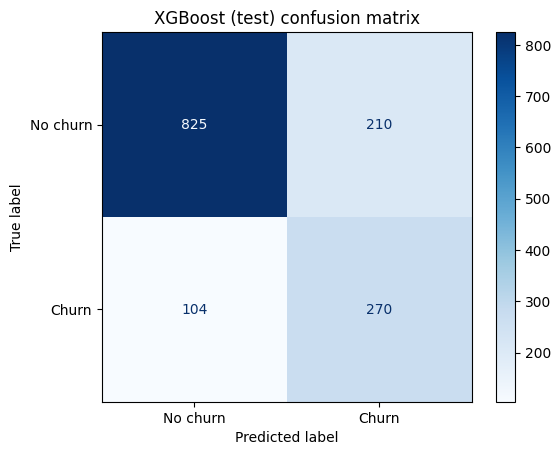

In [61]:
# Final evaluation on the test set
y_test_prob_ann = ann_model.predict(X_test_processed, verbose=0).ravel()
y_test_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_test_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

ann_test_result = evaluate_model(
    y_test,
    y_test_prob_ann,
    threshold=best_threshold,
    model_name="ANN (test)"
)

logistic_test_result = evaluate_model(
    y_test,
    y_test_prob_logistic,
    threshold=best_threshold,
    model_name="Logistic regression (test)"
)

xgb_test_result = evaluate_model(
    y_test,
    y_test_prob_xgb,
    threshold=best_threshold,
    model_name="XGBoost (test)"
)

In [62]:
#  Final comparison table
test_results = pd.DataFrame([
    ann_test_result,
    logistic_test_result,
    xgb_test_result
])

test_results.sort_values("F1", ascending=False)

,Model,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
2,XGBoost (test),0.33,0.777147,0.562500,0.721925,0.632319,0.650685
0,ANN (test),0.33,0.770050,0.552966,0.697861,0.617021,0.641098
1,Logistic regression (test),0.33,0.669269,0.440568,0.911765,0.594077,0.633133


In [63]:
#  Detailed classification report for the ANN
y_test_pred_ann = (y_test_prob_ann >= best_threshold).astype(int)

print(classification_report(
    y_test,
    y_test_pred_ann,
    target_names=["No churn", "Churn"],
    digits=4
))

              precision    recall  f1-score   support

    No churn     0.8794    0.7961    0.8357      1035
       Churn     0.5530    0.6979    0.6170       374

    accuracy                         0.7700      1409
   macro avg     0.7162    0.7470    0.7264      1409
weighted avg     0.7928    0.7700    0.7777      1409



In [64]:
# Analyze ANN mistakes
test_results_df = X_test.copy()
test_results_df["actual_churn"] = y_test.values
test_results_df["predicted_churn"] = y_test_pred_ann
test_results_df["churn_probability"] = y_test_prob_ann

false_positives = test_results_df[
    (test_results_df["actual_churn"] == 0) &
    (test_results_df["predicted_churn"] == 1)
]

false_negatives = test_results_df[
    (test_results_df["actual_churn"] == 1) &
    (test_results_df["predicted_churn"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

false_negatives.sort_values("churn_probability", ascending=False).head(10)

False positives: 211
False negatives: 113


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual_churn,predicted_churn,churn_probability
5715,Male,0,No,No,32,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),108.15,3432.90,1,0,0.327190
4823,Male,0,No,No,1,Yes,No,DSL,Yes,No,...,No,No,Month-to-month,Yes,Electronic check,53.95,53.95,1,0,0.325046
523,Female,0,No,No,23,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,No,Bank transfer (automatic),75.60,1758.60,1,0,0.324966
3638,Female,1,Yes,No,2,Yes,No,DSL,No,Yes,...,No,No,Month-to-month,No,Credit card (automatic),50.15,115.10,1,0,0.324084
110,Male,0,Yes,No,55,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,No,Month-to-month,Yes,Electronic check,96.75,5238.90,1,0,0.323716
1770,Female,1,No,No,41,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,113.20,4689.50,1,0,0.322667
180,Female,0,No,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,No,Bank transfer (automatic),29.95,29.95,1,0,0.318923
3362,Female,0,No,No,1,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Electronic check,54.90,54.90,1,0,0.317728
4740,Male,1,Yes,No,24,No,No phone service,DSL,Yes,No,...,No,Yes,Month-to-month,No,Bank transfer (automatic),39.10,971.30,1,0,0.314685
3251,Female,1,No,No,37,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),106.75,4056.75,1,0,0.314607


In [65]:
#  Save the ANN, preprocessor, and threshold
ann_model.save("churn_ann_model.keras")

import joblib

joblib.dump(preprocessor, "churn_preprocessor.joblib")
joblib.dump(best_threshold, "churn_best_threshold.joblib")

print("Model, preprocessor, and threshold saved.")

Model, preprocessor, and threshold saved.


In [67]:
#  Predict a new customer
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 3,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 89.10,
    "TotalCharges": 267.30
}])

new_customer_processed = preprocessor.transform(new_customer)

new_customer_probability = ann_model.predict(
    new_customer_processed,
    verbose=0
).ravel()[0]

new_customer_prediction = int(new_customer_probability >= best_threshold)

print(f"Churn probability: {new_customer_probability:.2%}")
print("Predicted class:", "Churn" if new_customer_prediction == 1 else "No churn")
print(f"Decision threshold: {best_threshold:.2f}")

Churn probability: 78.57%
Predicted class: Churn
Decision threshold: 0.33
